In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/raw/telco_churn_real.csv')
print(df.shape)
print(df.head())

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [4]:
# df["TotalCharges"].value_counts().head(10)
df[df["TotalCharges"].astype(str).str.strip() == ""]
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)
print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isna().sum())

float64
11


In [5]:
df[df["TotalCharges"].isna()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [6]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isna().sum())
print(df["TotalCharges"].dtype)

0
float64


In [7]:
df[df["tenure"] == 0][
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,0.0
753,0,20.25,0.0
936,0,80.85,0.0
1082,0,25.75,0.0
1340,0,56.05,0.0
3331,0,19.85,0.0
3826,0,25.35,0.0
4380,0,20.00,0.0
5218,0,19.70,0.0
6670,0,73.35,0.0


In [8]:
df["Churn"].value_counts()
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train: {y_train.value_counts(normalize=True)*100}")
print(f"Test: {y_test.value_counts(normalize=True)*100}")

Train: Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64
Test: Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


In [10]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Числовые:", numeric_features)
print("Категориальные:", categorical_features)

Числовые: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Категориальные: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression())
])
logreg_pipeline.fit(X_train, y_train)
y_pred = logreg_pipeline.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred, pos_label='Yes'))
print("Recall: ", recall_score(y_test, y_pred, pos_label='Yes'))
print("F1_score: ", f1_score(y_test, y_pred, pos_label='Yes'))
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

Accuracy:  0.8055358410220014
Precision:  0.6572327044025157
Recall:  0.5588235294117647
F1_score:  0.6040462427745664
[[926 109]
 [165 209]]


In [13]:
yes_pred_proba = logreg_pipeline.predict_proba(X_test)[:, 1]
threshold = 0.3
pred = [
    'Yes' if prob >= threshold else 'No'
    for prob in yes_pred_proba
]
print("Precision: ", precision_score(y_test, pred, pos_label="Yes"))
print("Recall: ", recall_score(y_test, pred, pos_label="Yes"))
print("F1_score: ", f1_score(y_test, pred, pos_label="Yes"))

Precision:  0.5193370165745856
Recall:  0.7540106951871658
F1_score:  0.6150490730643402


In [14]:
from sklearn.model_selection import cross_val_predict

logreg_pipeline_cv_pred = cross_val_predict(
    logreg_pipeline,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)

In [15]:
yes_cv_pred = logreg_pipeline_cv_pred[:, 1]
thresholds = np.arange(0.1, 0.91, 0.05)
best_cv_f1 = 0
best_threshold = None
for threshold in thresholds:
    predictions = [
        "Yes" if prob >= threshold else "No"
        for prob in yes_cv_pred
    ]
    current_f1 = f1_score(y_train, predictions, pos_label="Yes")
    if current_f1 >= best_cv_f1:
        best_cv_f1 = current_f1
        best_threshold = threshold
y_pred_03 = [
    "Yes" if prob >= best_threshold else "No"
    for prob in yes_pred_proba
]
print("Best threshold:", best_threshold)
print("Best F1:", best_cv_f1) 
print(confusion_matrix(y_test, y_pred_03, labels=["No", "Yes"]))

Best threshold: 0.30000000000000004
Best F1: 0.6324833702882483
[[774 261]
 [ 92 282]]


In [16]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42))
])
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remai

In [17]:
rf_pred = rf_pipeline.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, rf_pred))
print("Precision: ", precision_score(y_test, rf_pred, pos_label="Yes"))
print("Recall: ", recall_score(y_test, rf_pred, pos_label="Yes"))
print("F1-score: ", f1_score(y_test, rf_pred, pos_label="Yes"))
print(confusion_matrix(y_test, rf_pred, labels=["No", "Yes"]))

Accuracy:  0.7828246983676366
Precision:  0.6118421052631579
Recall:  0.49732620320855614
F1-score:  0.5486725663716814
[[917 118]
 [188 186]]


In [18]:
# rf_pred = rf_pipeline.predict(X_train)
# print("Accuracy: ", accuracy_score(y_train, rf_pred))
rf_pipeline_depth5 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])
rf_pipeline_depth5.fit(X_train, y_train)
rf_depth5_pred = rf_pipeline_depth5.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, rf_depth5_pred))
print("F1-score: ", f1_score(y_test, rf_depth5_pred, pos_label="Yes"))

Accuracy:  0.7927608232789212
F1-score:  0.5181518151815182


In [19]:
rf_depth5_pred = rf_pipeline_depth5.predict(X_train)
print("Accuracy: ", accuracy_score(y_train, rf_depth5_pred))
print("F1-score: ", f1_score(y_train, rf_depth5_pred, pos_label="Yes"))

Accuracy:  0.8008519701810437
F1-score:  0.5363636363636364


In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

param_grid = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [5, 10, 15, None],
    'model__min_samples_leaf': [1, 2, 5]
}
f1_scorer = make_scorer(f1_score, pos_label='Yes')

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    scoring = f1_scorer
)
rf_grid.fit(X_train, y_train)
print(rf_grid.best_params_)
print(rf_grid.best_score_)

{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 50}
0.5780606032903894


In [21]:
best_rf = rf_grid.best_estimator_
best_rf_pred = best_rf.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, best_rf_pred))
print("Precision: ", precision_score(y_test, best_rf_pred, pos_label="Yes"))
print("Recall: ", recall_score(y_test, best_rf_pred, pos_label="Yes"))
print("F1-score: ", f1_score(y_test, best_rf_pred, pos_label="Yes"))
print(confusion_matrix(y_test, best_rf_pred, labels=["No", "Yes"]))

Accuracy:  0.7970191625266146
Precision:  0.6456953642384106
Recall:  0.5213903743315508
F1-score:  0.5769230769230769
[[928 107]
 [179 195]]


In [22]:
from sklearn.model_selection import cross_val_predict

best_rf_cv_pred = cross_val_predict(best_rf, X_train, y_train, cv=5, method="predict_proba")
best_rf_yes_cv_pred = best_rf_cv_pred[:,1]
print(best_rf_yes_cv_pred.shape)

(5634,)


In [23]:
import numpy as np
rf_thresholds = np.arange(0.1, 0.95, 0.05)
best_rf_f1 = 0
best_rf_threshold = None

for threshold in rf_thresholds:
    predictions = [
        "Yes" if prob >= threshold else "No"
        for prob in best_rf_yes_cv_pred
    ]
    current_f1 = f1_score(y_train, predictions, pos_label="Yes")
    if current_f1 > best_rf_f1:
        best_rf_f1 = current_f1
        best_rf_threshold = threshold
print(best_rf_threshold)
print(best_rf_f1)

0.30000000000000004
0.6312056737588653


In [24]:
best_rf_yes_test_pred = best_rf.predict_proba(X_test)[:, 1]

predictions = [
    "Yes" if prob >= best_rf_threshold else "No"
    for prob in best_rf_yes_test_pred
]
print("Accuracy: ", accuracy_score(y_test, predictions))
print("Precision: ", precision_score(y_test, predictions, pos_label="Yes"))
print("Recall: ", recall_score(y_test, predictions, pos_label="Yes"))
print("F1-score: ", f1_score(y_test, predictions, pos_label="Yes"))
print(confusion_matrix(y_test, predictions, labels=["No", "Yes"]))

Accuracy:  0.7508871540099361
Precision:  0.5206463195691203
Recall:  0.7754010695187166
F1-score:  0.6229860365198711
[[768 267]
 [ 84 290]]


In [26]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    estimator=best_rf,
    X=X_test,
    y=y_test,
    n_repeats=5,
    random_state=42,
    scoring=f1_scorer
)
print(result.importances_mean)
print(result.importances_mean.shape)

[ 0.00388151  0.00908044 -0.0010614   0.00517669  0.05496313  0.00024178
  0.01276146  0.07280652  0.04730287  0.00447823  0.00534478  0.02136631
 -0.00301162  0.00603195  0.12251349  0.0170888   0.00795757  0.029419
  0.02910394]
(19,)


In [29]:
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
print(feature_importance.head(10))

             Feature  Importance
14          Contract    0.122513
7    InternetService    0.072807
4             tenure    0.054963
8     OnlineSecurity    0.047303
17    MonthlyCharges    0.029419
18      TotalCharges    0.029104
11       TechSupport    0.021366
15  PaperlessBilling    0.017089
6      MultipleLines    0.012761
1      SeniorCitizen    0.009080


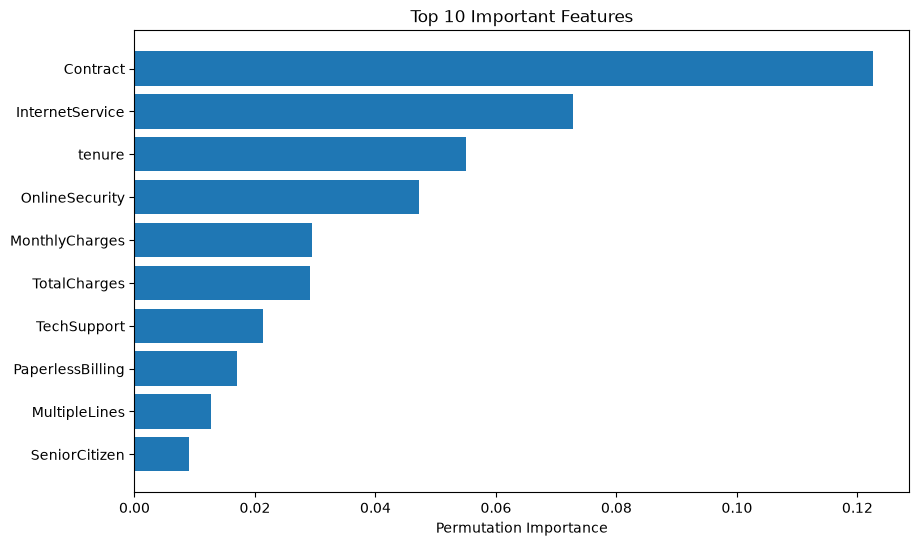

In [30]:
import matplotlib.pyplot as plt

top10 = feature_importance.head(10)
plt.figure(figsize=(10, 6))
plt.barh(top10["Feature"], top10["Importance"])
plt.gca().invert_yaxis()

plt.xlabel("Permutation Importance")
plt.title("Top 10 Important Features")
plt.show()


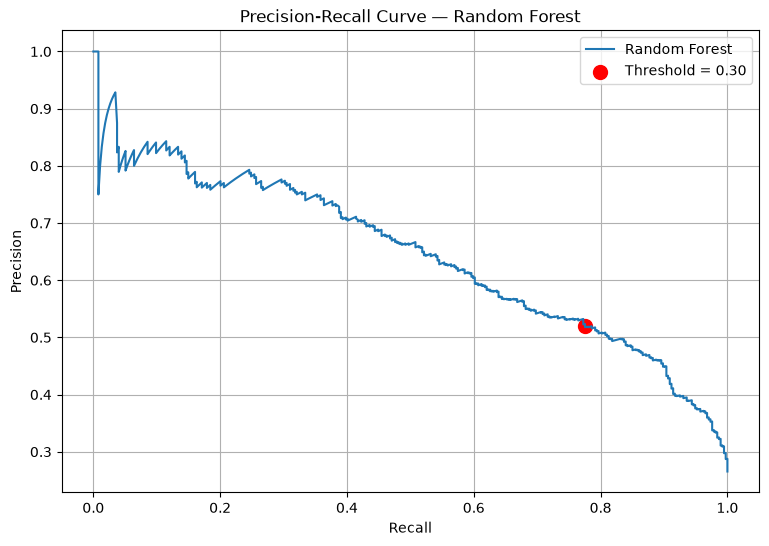

In [31]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_true=y_test,
    y_score=best_rf_yes_test_pred,
    pos_label="Yes"
)

plt.figure(figsize=(9, 6))
plt.plot(recall, precision, label="Random Forest")

threshold_predictions = [
    "Yes" if prob >= best_rf_threshold else "No"
    for prob in best_rf_yes_test_pred
]

precision_03 = precision_score(
    y_test, threshold_predictions, pos_label="Yes"
)
recall_03 = recall_score(
    y_test, threshold_predictions, pos_label="Yes"
)

plt.scatter(
    recall_03,
    precision_03,
    color="red",
    s=100,
    label=f"Threshold = {best_rf_threshold:.2f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Random Forest")
plt.legend()
plt.grid(True)
plt.show()

In [33]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(best_rf, model_dir / "churn_model_real.joblib")
joblib.dump(best_rf_threshold, model_dir / "churn_threshold_real.joblib")
loaded_model = joblib.load(
    model_dir / "churn_model_real.joblib"
)

loaded_threshold = joblib.load(
    model_dir / "churn_threshold_real.joblib"
)
probabilities = loaded_model.predict_proba(X_test.head(3))[:, 1]

predictions = [
    "Yes" if prob >= loaded_threshold else "No"
    for prob in probabilities
]

print("Probabilities:", probabilities)
print("Predictions:", predictions)
print("Threshold:", loaded_threshold)

Probabilities: [0.00800102 0.74756779 0.05200802]
Predictions: ['No', 'Yes', 'No']
Threshold: 0.30000000000000004
